# Supplemental Figure 4, Panel E

Heatmaps showing transcriptional induction at early (1h) and late (6h) induced genes for both IFNg and Dex

*Outputs: ifn_1h_hm.pdf, ifn_6h_hm.pdf, dex_1h_hm.pdf, dex_6h_hm.pdf*

# Setup

In [1]:
# load packages
library(tidyverse)
library(RColorBrewer)
library(pheatmap)
library(gridExtra)
library(here)
here::i_am("figures/SuppFig4/PanelE/PanelE_heatmap.ipynb")
theme_set(theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=15)))

sessionInfo()

dex_col <- "#5791c9"
ifn_col <- "#149e77"

#function to generate heatmap given table of TPMs, list of table rows to plot, and treatment conditions
hm <- function(table, rows, treatments, color, scale="row"){
    temp <- table[rows,]
    names <- colnames(temp)
    condition <-  gsub("_r.*$", "", names) #extract condition (dose + time) as well as dose and time separately
    treatment <- gsub("_T.*$", "", condition)
    keep_cols <- which(treatment %in% treatments,)
    temp <- temp[,keep_cols]
    pheatmap(log2(temp+1), cluster_rows=FALSE, cluster_cols=FALSE, color=colorRampPalette(c("white", color))(100), scale=scale , show_rownames=FALSE, cellheight = 1,breaks=seq(-2,2,length.out=100), main=paste("n=", length(rows)))
}

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine


here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/figures/SuppFig4/PanelE

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] here_1.0.2         gridExtra_2.3      pheatmap_1.0.12    RColorBrewer_1.1-3
 [5] lubridate_1.9.4    forcats_1.0.0      stringr_1.5.1      dplyr_1.1.4       
 [9] purrr_1.0.2        readr_2.1.5        tidyr_1.3.1        tibble_3.2.1      
[13] ggplot2_3.5.2      tidyverse_2.0.0   

loaded 

# Load data

In [2]:
# load sample data (col.data), gene metadata (row.data) and table of TPMs

# TPMs
tpms <- read.delim(
  here("figures", "Figure4", "IFNy_Dex_DEGs_TPMs.tsv"),
  sep = "\t"
)

# gene-level metadata
row.data <- read.delim(
  here("figures", "Figure4", "IFNy_Dex_DEGs_rowdata.tsv"),
  sep = "\t"
)

# sample-level metadata
col.data <- read.delim(
  here("figures", "Figure4", "IFNy_Dex_DEGs_coldata.tsv"),
  sep = "\t"
)

colnames(tpms) <- paste0(col.data$group, "_", col.data$replicate)

# read in differential expression analysis results

# stimulus vs vehicle
ifn_1h <- read.delim(
  here("inputs", "DEGs", "GM12878", "BAFinh_stimulus", "IFNy_1h_DEGs.tsv"),
  sep = "\t"
)

ifn_6h <- read.delim(
  here("inputs", "DEGs", "GM12878", "BAFinh_stimulus", "IFNy_6h_DEGs.tsv"),
  sep = "\t"
)

dex_1h <- read.delim(
  here("inputs", "DEGs", "GM12878", "BAFinh_stimulus", "Dex_1h_DEGs.tsv"),
  sep = "\t"
)

dex_6h <- read.delim(
  here("inputs", "DEGs", "GM12878", "BAFinh_stimulus", "Dex_6h_DEGs.tsv"),
  sep = "\t"
)

# Define 1h-induced and 6h-induced gene sets

In [3]:
#define 1h-induced and 6h-induced gene sets
#order genes within each set by level of induction

ifn_up_1h <- which((ifn_1h$change == "up" & ifn_6h$change != "up") | (ifn_1h$change == "up" & ifn_6h$change == "up"))
ifn_up_1h_ordered <- (ifn_1h[ifn_up_1h,] %>% mutate(rownum=ifn_up_1h) %>% arrange(desc((log2FoldChange*baseMean)-baseMean)))$rownum

ifn_up_6h <- which(ifn_1h$change != "up" & ifn_6h$change == "up")
ifn_up_6h_ordered <- (ifn_6h[ifn_up_6h,] %>% mutate(rownum=ifn_up_6h)  %>% arrange(desc((log2FoldChange*baseMean)-baseMean)))$rownum

dex_up_1h <- which((dex_1h$change == "up" & dex_6h$change != "up") | (dex_1h$change == "up" & dex_6h$change == "up"))
dex_up_1h_ordered <- (dex_1h[dex_up_1h,] %>% mutate(rownum=dex_up_1h)  %>% arrange(desc((log2FoldChange*baseMean)-baseMean)))$rownum

dex_up_6h <- which(dex_1h$change != "up" & dex_6h$change == "up")
dex_up_6h_ordered <- (dex_6h[dex_up_6h,] %>% mutate(rownum=dex_up_6h)  %>% arrange(desc((log2FoldChange*baseMean)-baseMean)))$rownum

# Generate plots

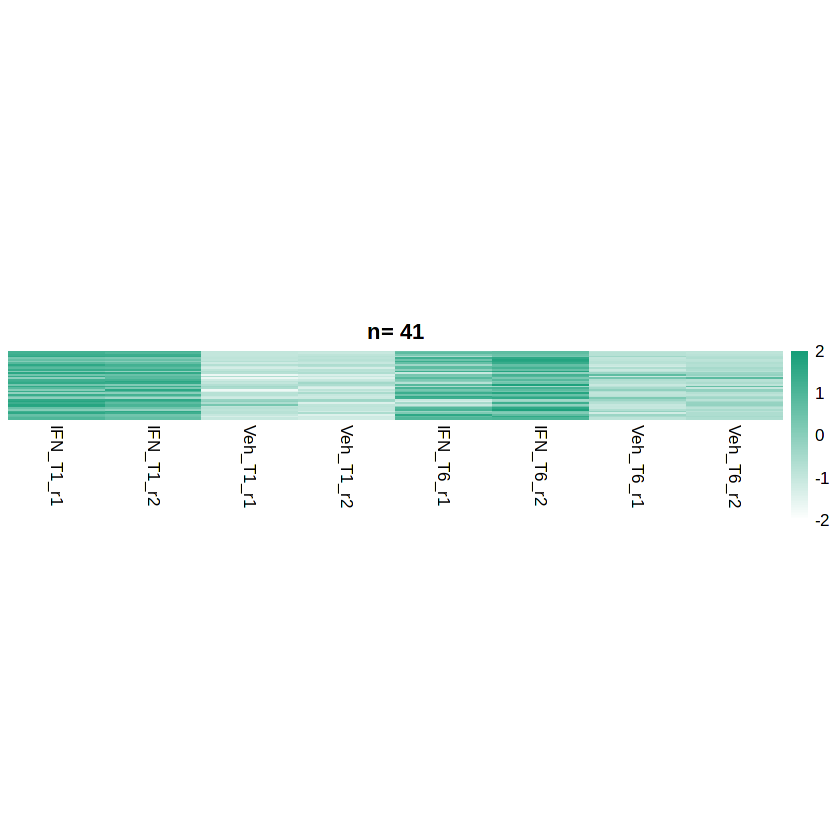

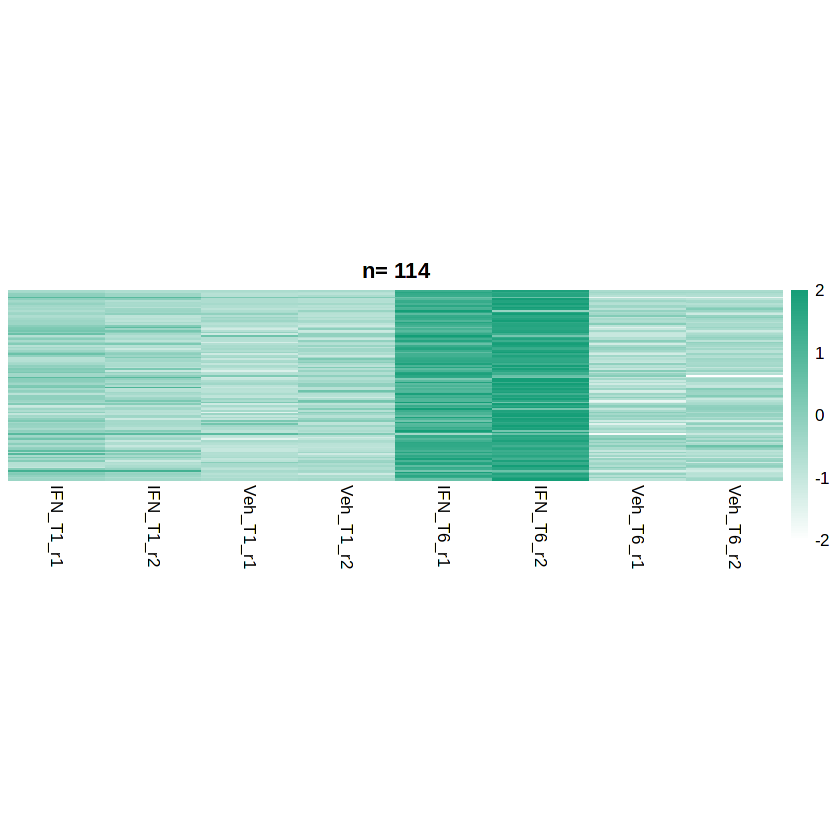

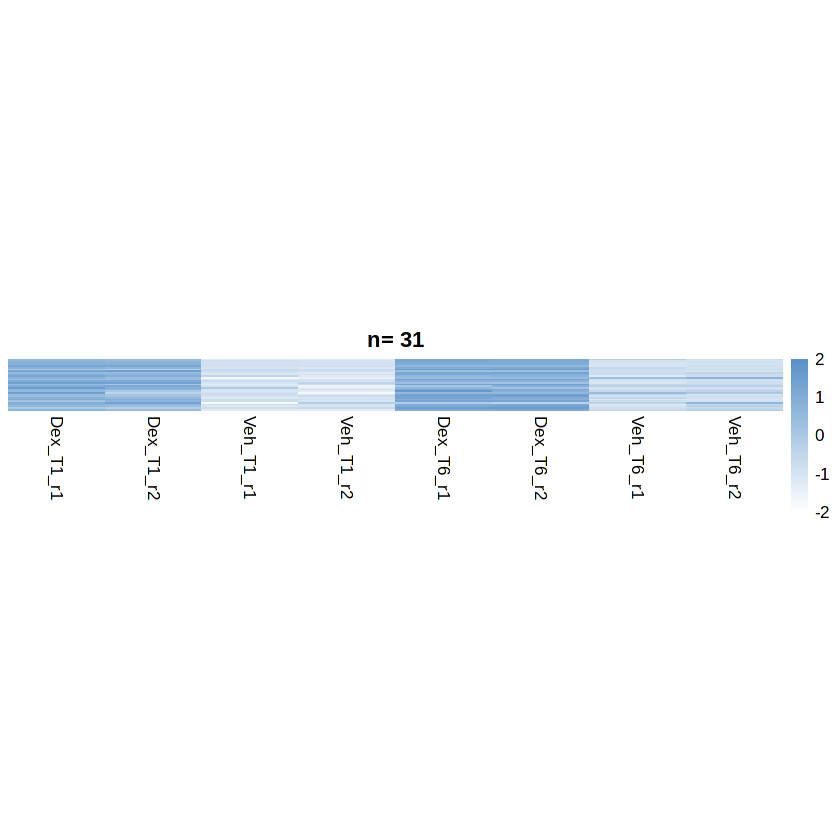

pdf 
  2

pdf 
  2

pdf 
  2

pdf 
  2

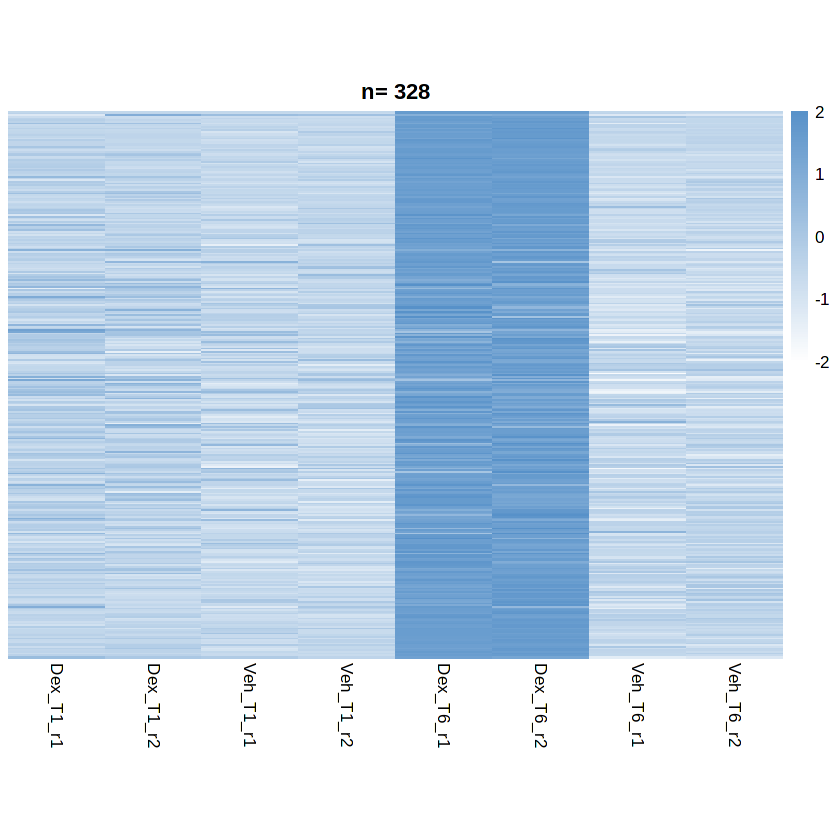

In [4]:
#generate heatmaps
ifn_1h_hm <- hm(tpms,ifn_up_1h_ordered, c("Veh", "IFN"), ifn_col, scale="row")
ifn_6h_hm <- hm(tpms,ifn_up_6h_ordered, c("Veh", "IFN"), ifn_col, scale="row")
dex_1h_hm <- hm(tpms,dex_up_1h_ordered, c("Veh", "Dex"), dex_col, scale="row")
dex_6h_hm <- hm(tpms,dex_up_6h_ordered, c("Veh", "Dex"), dex_col, scale="row")

pdf("ifn_1h_hm.pdf", width=2, height=2)
ifn_1h_hm
dev.off()

pdf("ifn_6h_hm.pdf", width=2, height=4)
ifn_6h_hm
dev.off()

pdf("dex_1h_hm.pdf", width=2, height=2)
dex_1h_hm
dev.off()

pdf("dex_6h_hm.pdf", width=2, height=6)
dex_6h_hm
dev.off()